[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/AIforPhilanthropy/eduall/blob/main/traditionalAI_groupwork/01_unsupervised_clustering.ipynb)

# EduAll — Unsupervised Clustering for Grant Allocation

**Input:** `data/EduAll_500_Applications_Dataset.csv` (500 synthetic grant applications to the fictional
EduAll Foundation). **Goal:** group applicants who are alike across several relevant criteria at once,
using a distance metric that handles quantitative and qualitative (categorical) variables together, embed
that distance structure in two dimensions with UMAP, cluster it with the Leiden algorithm, and turn the
cluster structure into a concrete rule for splitting a fixed CHF 500,000 budget.

Pipeline: **mixed-type (Gower) distance matrix &rarr; UMAP embedding &rarr; k-nearest-neighbour graph
&rarr; Leiden clustering &rarr; cluster profiling &rarr; budget allocation.**

No labels are used anywhere in this notebook — the dataset does not record who was actually funded, so
this is genuinely unsupervised. Runs standalone in Google Colab; no other files are required besides the
CSV.

In [ ]:
# --- Get the data -------------------------------------------------------------------------------
# On Google Colab this cell downloads the course repository (data + notebooks) from GitHub and moves into this
# notebook's folder, so every data path below works as on the course computers. Locally it does nothing.
import os, pathlib, subprocess
REPO_URL = "https://github.com/AIforPhilanthropy/eduall.git"
NOTEBOOK_DIR = "traditionalAI_groupwork"          # this notebook's folder inside the repository
here = pathlib.Path.cwd()
if not any((p / "data" / "EduAll_500_Applications_Dataset.csv").exists() for p in [here, *here.parents]):
    if not pathlib.Path("/content/eduall").exists():
        subprocess.run(["git", "clone", "--depth", "1", REPO_URL, "/content/eduall"], check=True)
    os.chdir(pathlib.Path("/content/eduall") / NOTEBOOK_DIR)
print("working directory:", os.getcwd())

## 0. Setup

In [1]:
import importlib.util, sys, subprocess
need = [pkg for pkg, mod in [("umap-learn", "umap"), ("python-igraph", "igraph"), ("leidenalg", "leidenalg")]
        if importlib.util.find_spec(mod) is None]
if need:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *need], check=True)
print("ready")

ready


In [2]:
import pathlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import networkx as nx
import igraph as ig
import leidenalg
import umap

SEED = 42
np.random.seed(SEED)
mpl.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                      "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})
pd.set_option("display.width", 140)

## 1. Load the data

Works locally (run from `traditionalAI_groupwork/`) and in Colab (upload prompt if the file is not found next to the notebook).

In [3]:
CSV_CANDIDATES = [
    pathlib.Path("../data/EduAll_500_Applications_Dataset.csv"),
    pathlib.Path("data/EduAll_500_Applications_Dataset.csv"),
    pathlib.Path("EduAll_500_Applications_Dataset.csv"),
]
csv_path = next((p for p in CSV_CANDIDATES if p.exists()), None)
if csv_path is None:
    try:
        from google.colab import files
        print("CSV not found next to the notebook -- please upload EduAll_500_Applications_Dataset.csv")
        uploaded = files.upload()
        csv_path = pathlib.Path(next(iter(uploaded)))
    except ImportError:
        raise FileNotFoundError(
            "Could not find EduAll_500_Applications_Dataset.csv. "
            "Place it at ../data/ relative to this notebook, or upload it.")

raw = pd.read_csv(csv_path, keep_default_na=False)
print(raw.shape)
raw.head(3)

(500, 44)


,student_id,application_date,age,gender,country_origin,gni_tier,geographic_region,dependent_children,study_level,university,...,risk_housing_insecurity,risk_family_emergency,risk_language_barrier,risk_parent_student,risk_undocumented_status,resilience_volunteer_experience,resilience_work_experience,resilience_leadership_role,resilience_community_engagement,resilience_overcame_adversity
0,STU000001,7/24/26,21,Male,Indonesia,2,Southeast Asia,0,Bachelor's,University of Geneva,...,1,0,0,0,0,0,1,1,1,0
1,STU000002,8/18/26,27,Non-binary,Pakistan,1,South Asia,0,Master's,University of Lausanne,...,0,0,0,0,0,0,1,0,0,1
2,STU000003,7/17/26,27,Male,Vietnam,2,Southeast Asia,0,Master's,University of Geneva,...,1,0,0,0,0,0,1,0,0,0


## 2. Variables used for the distance metric

A grant committee's decision does not rest on one number: it weighs **financial need, academic
situation, declared risk/resilience circumstances and the call's own stated priorities** together. We
pick variables that plausibly matter for *that* decision and deliberately leave out variables that have
no stated role in it (raw country name, university, field of study, gender) — the policy-relevant
information in "country" is already captured by `gni_tier` and `geographic_region`, which the Grant Call
names explicitly as priority criteria, without the extra, ethically sensitive granularity of nationality
itself.

**Quantitative** (7): `age`, `gpa`, `financial_need_chf`, `savings_chf`, `progress_ratio`
(courses completed / courses required for the study level), `risk_count` (0-8), `resil_count` (0-5).

**Qualitative / categorical** (7): `study_level`, `gni_tier`, `geographic_region`, `residency_permit`,
`study_mode`, `academic_standing`, `has_external_scholarship`.

`gni_tier` and `has_external_scholarship` are coded as integers in the CSV but used here as *categories*
(a tier is a priority label, not a quantity to subtract or average).

In [4]:
REQUIRED = {"Bachelor's": 40, "Master's": 12, "Doctoral": 12}
RISK_COLS = ["risk_first_generation", "risk_refugee_asylum", "risk_disability", "risk_housing_insecurity",
             "risk_family_emergency", "risk_language_barrier", "risk_parent_student",
             "risk_undocumented_status"]
RESIL_COLS = ["resilience_volunteer_experience", "resilience_work_experience", "resilience_leadership_role",
              "resilience_community_engagement", "resilience_overcame_adversity"]

df = raw.copy()
df["progress_ratio"] = (df.courses_completed / df.study_level.map(REQUIRED)).clip(0, 1)
df["risk_count"] = df[RISK_COLS].sum(axis=1)
df["resil_count"] = df[RESIL_COLS].sum(axis=1)

QUANTI = ["age", "gpa", "financial_need_chf", "savings_chf", "progress_ratio", "risk_count", "resil_count"]
QUALI = ["study_level", "gni_tier", "geographic_region", "residency_permit", "study_mode",
         "academic_standing", "has_external_scholarship"]

X = df.set_index("student_id")[QUANTI + QUALI].copy()
for c in QUALI:
    X[c] = X[c].astype(str)
X.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
age,500.0,NaN,NaN,NaN,29.29,6.839844,18.0,24.0,28.0,32.0,45.0
gpa,500.0,NaN,NaN,NaN,2.9878,0.455021,2.0,2.69,3.03,3.3,4.0
financial_need_chf,500.0,NaN,NaN,NaN,940.906,771.54644,0.0,0.0,1008.0,1629.25,2411.0
savings_chf,500.0,NaN,NaN,NaN,3214.376,4639.000789,0.0,0.0,0.0,6457.5,14987.0
progress_ratio,500.0,NaN,NaN,NaN,0.320833,0.15467,0.025,0.175,0.3125,0.416667,0.725
risk_count,500.0,NaN,NaN,NaN,1.546,1.22265,0.0,1.0,1.0,2.0,6.0
resil_count,500.0,NaN,NaN,NaN,2.634,1.191168,0.0,2.0,3.0,3.0,5.0
study_level,500,3,Bachelor's,242,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gni_tier,500,3,1,249,NaN,NaN,NaN,NaN,NaN,NaN,NaN
geographic_region,500,7,South Asia,116,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 3. A mixed-type distance matrix (Gower distance)

[Gower's (1971)](https://doi.org/10.2307/2528823) distance is the standard way to compare records that mix
quantitative and categorical variables: for a quantitative variable it is the absolute difference scaled
by that variable's range (so every quantitative variable contributes on the same 0-1 scale regardless of
its units); for a categorical variable it is 0 if two applicants share the category and 1 otherwise. The
overall distance between two applicants is the plain average of these per-variable distances (every
variable gets equal weight, since none of the 14 is a priori more important than another from a pure
similarity-matching standpoint — the committee's priorities enter later, at the allocation stage, not at
the clustering stage).

distance matrix: (500, 500)   range: 0.0 - 0.853


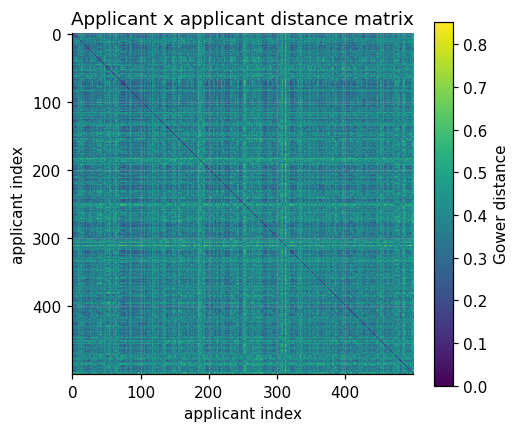

In [5]:
def gower_distance_matrix(X: pd.DataFrame, quanti: list, quali: list) -> np.ndarray:
    n = len(X)
    D = np.zeros((n, n))
    nvars = len(quanti) + len(quali)
    for c in quanti:
        v = X[c].to_numpy(dtype=float)
        rng = v.max() - v.min()
        d = np.abs(v[:, None] - v[None, :]) / (rng if rng > 0 else 1.0)
        D += d
    for c in quali:
        v = X[c].to_numpy()
        d = (v[:, None] != v[None, :]).astype(float)
        D += d
    return D / nvars

D = gower_distance_matrix(X, QUANTI, QUALI)
print("distance matrix:", D.shape, "  range:", D.min().round(3), "-", D.max().round(3))
plt.figure(figsize=(5, 4.3))
plt.imshow(D, cmap="viridis")
plt.colorbar(label="Gower distance")
plt.title("Applicant x applicant distance matrix")
plt.xlabel("applicant index"); plt.ylabel("applicant index")
plt.show()

## 4. UMAP embedding

UMAP is given the distance matrix directly (`metric="precomputed"`), so the 2D layout reflects Gower
distance, not a Euclidean distance on some arbitrary encoding of the raw columns.

/opt/anaconda3/lib/python3.12/site-packages/umap/umap_.py:1865: UserWarning: using precomputed metric; inverse_transform will be unavailable
  warn("using precomputed metric; inverse_transform will be unavailable")
/opt/anaconda3/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


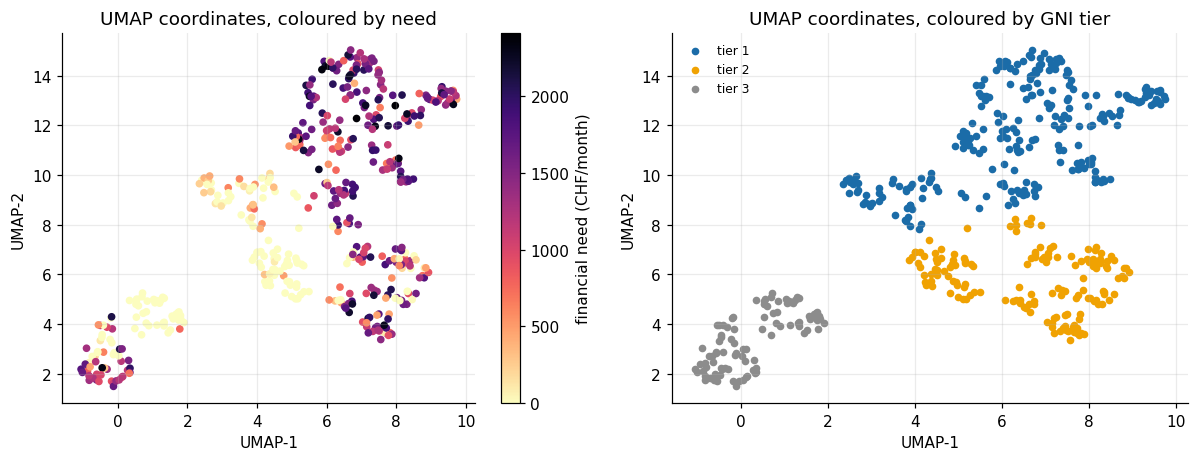

In [6]:
reducer = umap.UMAP(metric="precomputed", n_neighbors=15, min_dist=0.3, random_state=SEED)
emb = reducer.fit_transform(D)
X["umap_x"], X["umap_y"] = emb[:, 0], emb[:, 1]

fig, axes = plt.subplots(1, 2, figsize=(11, 4.3))
sc0 = axes[0].scatter(X.umap_x, X.umap_y, c=df.financial_need_chf.values, cmap="magma_r", s=16)
plt.colorbar(sc0, ax=axes[0], label="financial need (CHF/month)")
axes[0].set_title("UMAP coordinates, coloured by need")
for tier, col in zip(["1", "2", "3"], ["#1b6ca8", "#f0a202", "#8c8c8c"]):
    m = X.gni_tier == tier
    axes[1].scatter(X.loc[m, "umap_x"], X.loc[m, "umap_y"], s=16, color=col, label=f"tier {tier}")
axes[1].set_title("UMAP coordinates, coloured by GNI tier")
axes[1].legend(frameon=False, fontsize=8)
for a in axes:
    a.set_xlabel("UMAP-1"); a.set_ylabel("UMAP-2")
plt.tight_layout(); plt.show()

## 5. A nearest-neighbour graph, and Leiden clustering

We connect every applicant to their $k$ nearest neighbours in Gower distance (a sparse, local
similarity graph — much more informative for community detection than a fully-connected graph), weight
each edge by similarity $1 - d_{ij}$, and run the **Leiden algorithm** (Traag, Waltman & van Eck, 2019)
to find communities that maximise modularity. The same graph is drawn with the UMAP coordinates as its
layout, so the 2D picture and the network are the same object seen two ways.

In [7]:
K = 12
n = len(X)
nbrs = np.argsort(D, axis=1)[:, 1:K + 1]   # exclude self (distance 0 to itself, column 0)
edges, weights = [], []
seen = set()
for i in range(n):
    for j in nbrs[i]:
        e = (min(i, j), max(i, j))
        if e not in seen:
            seen.add(e)
            edges.append(e)
            weights.append(1 - D[i, j])

g = ig.Graph(n=n, edges=edges)
g.vs["student_id"] = list(X.index)
partition = leidenalg.find_partition(g, leidenalg.RBConfigurationVertexPartition,
                                      weights=weights, seed=SEED, resolution_parameter=1.0)
X["cluster"] = partition.membership
k_clusters = X["cluster"].nunique()
print(f"{k_clusters} Leiden clusters, sizes:", X["cluster"].value_counts().sort_index().to_dict())

10 Leiden clusters, sizes: {0: 61, 1: 58, 2: 58, 3: 56, 4: 55, 5: 49, 6: 47, 7: 43, 8: 40, 9: 33}


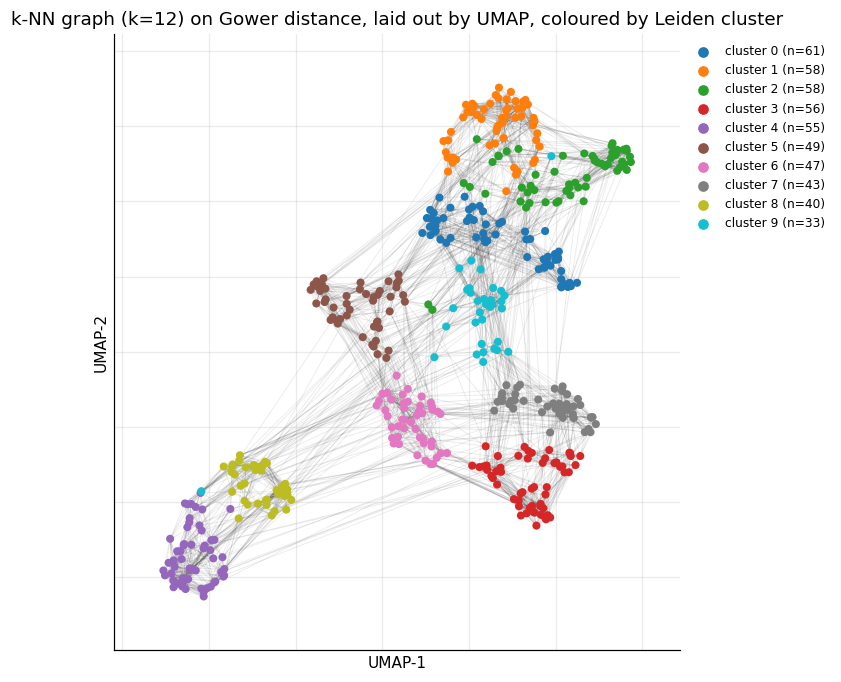

In [8]:
pos = {i: (X.umap_x.iat[i], X.umap_y.iat[i]) for i in range(n)}
G = nx.Graph(); G.add_nodes_from(range(n)); G.add_weighted_edges_from([(a, b, w) for (a, b), w in zip(edges, weights)])
palette = plt.cm.tab10(np.linspace(0, 1, max(k_clusters, 10)))
node_colors = [palette[c] for c in X["cluster"]]

fig, ax = plt.subplots(figsize=(7, 6.3))
nx.draw_networkx_edges(G, pos, ax=ax, alpha=0.08, width=0.6)
nx.draw_networkx_nodes(G, pos, ax=ax, node_size=28, node_color=node_colors, linewidths=0)
for c in sorted(X["cluster"].unique()):
    ax.scatter([], [], color=palette[c], label=f"cluster {c} (n={int((X.cluster==c).sum())})")
ax.legend(frameon=False, fontsize=8, loc="upper left", bbox_to_anchor=(1.0, 1.0))
ax.set_title(f"k-NN graph (k={K}) on Gower distance, laid out by UMAP, coloured by Leiden cluster")
ax.set_xlabel("UMAP-1"); ax.set_ylabel("UMAP-2")
plt.tight_layout(); plt.show()

## 6. What does each cluster actually look like?

Before turning clusters into money, we need to know what distinguishes them: is a cluster "high need",
"academically at risk", "tier-1 and far from done", or something else? This is exactly the plausibility
check a committee would want before trusting an algorithm's groups.

In [9]:
profile = X.groupby("cluster").agg(
    n=("age", "size"),
    mean_age=("age", "mean"), mean_gpa=("gpa", "mean"),
    mean_need_chf=("financial_need_chf", "mean"), mean_savings_chf=("savings_chf", "mean"),
    mean_progress=("progress_ratio", "mean"), mean_risk=("risk_count", "mean"),
    mean_resil=("resil_count", "mean"),
    pct_tier1=("gni_tier", lambda s: (s == "1").mean() * 100),
    pct_at_risk=("academic_standing", lambda s: (s == "At Risk").mean() * 100),
    pct_part_time=("study_mode", lambda s: (s == "Part-time").mean() * 100),
    pct_pending=("residency_permit", lambda s: (s == "Pending").mean() * 100),
).round(1).sort_values("mean_need_chf", ascending=False)
profile

,n,mean_age,mean_gpa,mean_need_chf,mean_savings_chf,mean_progress,mean_risk,mean_resil,pct_tier1,pct_at_risk,pct_part_time,pct_pending
cluster,,,,,,,,,,,,
1,58,28.4,3.1,1631.8,3379.2,0.3,1.8,2.7,100.0,8.6,0.0,5.2
2,58,29.7,3.2,1452.7,3101.3,0.3,1.6,2.8,100.0,5.2,3.4,6.9
9,33,25.9,2.2,1371.2,1819.6,0.4,1.6,3.3,69.7,100.0,0.0,9.1
0,61,25.6,3.0,1341.1,3865.2,0.5,1.5,2.5,100.0,0.0,0.0,4.9
3,56,30.0,3.2,1188.2,2878.4,0.3,1.4,2.2,0.0,0.0,0.0,1.8
7,43,25.3,3.1,950.0,3764.6,0.5,1.5,2.3,0.0,0.0,0.0,4.7
4,55,26.0,3.0,863.6,3433.2,0.3,1.4,2.4,0.0,14.5,0.0,0.0
5,49,33.7,2.9,161.2,3360.7,0.3,2.0,2.6,100.0,22.4,100.0,0.0
6,47,35.4,2.8,19.9,3426.7,0.2,1.4,2.8,0.0,27.7,100.0,0.0


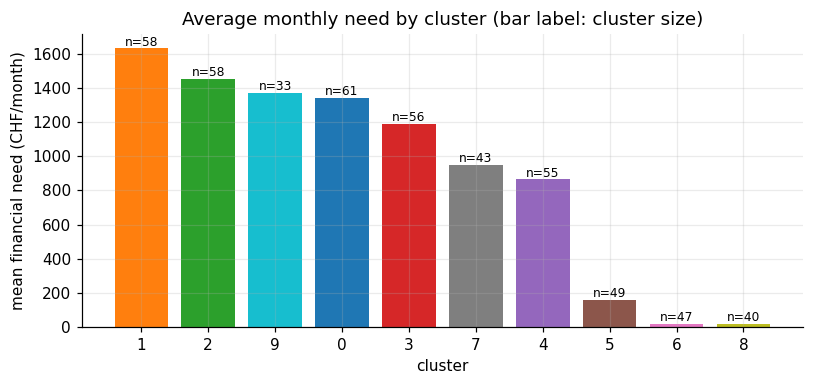

In [10]:
fig, ax = plt.subplots(figsize=(7.5, 3.6))
order = profile.index
ax.bar(order.astype(str), profile.mean_need_chf, color=[palette[c] for c in order])
for i, c in enumerate(order):
    ax.text(i, profile.mean_need_chf.loc[c] + 15, f"n={profile.n.loc[c]:.0f}", ha="center", fontsize=8)
ax.set_xlabel("cluster"); ax.set_ylabel("mean financial need (CHF/month)")
ax.set_title("Average monthly need by cluster (bar label: cluster size)")
plt.tight_layout(); plt.show()

## 7. From clusters to a CHF 500,000 decision

Three allocation policies are easy to write down and all three are wrong on their own:

* **Give the whole budget to one cluster** (e.g. the highest-need one) — rejected: it would mean a
  whole *profile* of applicants (part-time students, a particular region, an academic situation) is
  entirely excluded, no matter how strong an individual case within it is. A foundation that wants to
  reach a diverse applicant pool cannot defend funding zero applicants from several of its own clusters.
* **Split the budget equally, person by person, ignoring clusters** — rejected: it ignores that need is
  not uniform; clusters with systematically higher need would be under-served relative to their actual
  shortfall.
* **Split the budget equally, cluster by cluster, ignoring need** — rejected: a small, low-need cluster
  would receive the same envelope as a large, high-need one.

The rule used here is a hybrid, closer to how a foundation board actually reasons about a portfolio of
sub-populations:

1. **A reach floor** (10% of the budget) is split *equally across clusters*. This guarantees every
   profile the clustering surfaced gets some consideration, regardless of its size or average need —
   a deliberate equity floor, not a need calculation.
2. **The remaining 90%** is split *proportionally to each cluster's total eligible request* — the
   cluster that collectively asks for more of the capped, legitimate need receives a correspondingly
   larger share.
3. **Within each cluster**, applicants are funded in descending order of need until that cluster's
   combined envelope (floor + need share) runs out; the last applicant who does not fully fit receives
   a *partial* award for exactly what remains, so the envelope is used in full rather than left idle.

An applicant's request is their monthly need annualised (`financial_need_chf * 12`), capped at the
Grant Call's own published annual maximum per study level (`Bachelor's 8'000, Master's 6'500,
Doctoral 5'000` CHF) — the same cap the call applies regardless of which analysis produced the
recommendation.

In [11]:
BUDGET = 500_000
CAP = {"Bachelor's": 8_000, "Master's": 6_500, "Doctoral": 5_000}
FLOOR_SHARE = 0.10

df_idx = df.set_index("student_id")
request = np.minimum(df_idx.financial_need_chf * 12, df_idx.study_level.map(CAP))
X["request_chf"] = request
eligible = X.request_chf > 0
print(f"{eligible.sum()} of {len(X)} applicants have a positive, capped annual request")

cluster_request = X.loc[eligible].groupby("cluster").request_chf.sum()
floor_pool = BUDGET * FLOOR_SHARE
need_pool = BUDGET * (1 - FLOOR_SHARE)
cluster_envelope = (floor_pool / k_clusters) + need_pool * cluster_request / cluster_request.sum()
cluster_envelope.name = "envelope_chf"
cluster_envelope.round(0).to_frame()

361 of 500 applicants have a positive, capped annual request


,envelope_chf
cluster,
0,97126.0
1,73205.0
2,72046.0
3,60518.0
4,54201.0
5,22868.0
6,7170.0
7,55210.0
8,6259.0


In [12]:
award = pd.Series(0.0, index=X.index)
for c, env in cluster_envelope.items():
    pool = X.index[(X.cluster == c) & eligible]
    order = X.loc[pool, "request_chf"].sort_values(ascending=False).index
    left = env
    for sid in order:
        r = X.at[sid, "request_chf"]
        give = min(r, left)
        award[sid] = give
        left -= give
        if left <= 0:
            break
X["award_chf"] = award

print(f"total awarded: CHF {award.sum():,.0f} of CHF {BUDGET:,.0f} budget")
print(f"applicants funded: {(award > 0).sum()} of {eligible.sum()} eligible ({len(X)} total)")

total awarded: CHF 500,000 of CHF 500,000 budget
applicants funded: 75 of 361 eligible (500 total)


In [13]:
summary = X.groupby("cluster").agg(
    n=("award_chf", "size"), n_eligible=("request_chf", lambda s: (s > 0).sum()),
    n_funded=("award_chf", lambda s: (s > 0).sum()),
    total_request_chf=("request_chf", "sum"), total_award_chf=("award_chf", "sum"),
).round(0)
summary["coverage_pct"] = (summary.total_award_chf / summary.total_request_chf * 100).round(1)
summary = summary.join(cluster_envelope.round(0))
summary

,n,n_eligible,n_funded,total_request_chf,total_award_chf,coverage_pct,envelope_chf
cluster,,,,,,,
0,61,61,13,475800,97126.0,20.4,97126.0
1,58,57,12,352252,73205.0,20.8,73205.0
2,58,56,12,346268,72046.0,20.8,72046.0
3,56,50,10,286732,60518.0,21.1,60518.0
4,55,41,7,254108,54201.0,21.3,54201.0
5,49,23,4,92280,22868.0,24.8,22868.0
6,47,4,2,11208,7170.0,64.0,7170.0
7,43,37,7,259316,55210.0,21.3,55210.0
8,40,1,1,6500,6259.0,96.3,6259.0


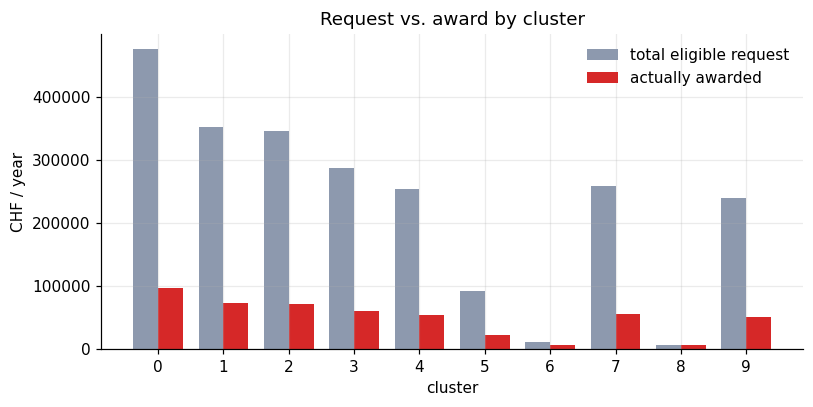

In [14]:
fig, ax = plt.subplots(figsize=(7.5, 3.8))
width = 0.38
xpos = np.arange(len(summary))
ax.bar(xpos - width/2, summary.total_request_chf, width, label="total eligible request", color="#8d99ae")
ax.bar(xpos + width/2, summary.total_award_chf, width, label="actually awarded", color="#d62828")
ax.set_xticks(xpos, [str(i) for i in summary.index])
ax.set_xlabel("cluster"); ax.set_ylabel("CHF / year"); ax.set_title("Request vs. award by cluster")
ax.legend(frameon=False)
plt.tight_layout(); plt.show()

## 8. A robustness check: does the number of neighbours change the story?

Leiden clustering depends on the resolution of the neighbourhood graph ($k$). We refit for a small range
of $k$ and compare how many clusters result and how much the awarded total per applicant moves, so the
committee can see whether the allocation is a fragile artefact of one specific choice of $k$ or a stable
pattern.

In [15]:
def cluster_and_allocate(k):
    nbrs_k = np.argsort(D, axis=1)[:, 1:k + 1]
    e, w, s = [], [], set()
    for i in range(n):
        for j in nbrs_k[i]:
            key = (min(i, j), max(i, j))
            if key not in s:
                s.add(key); e.append(key); w.append(1 - D[i, j])
    gg = ig.Graph(n=n, edges=e)
    part = leidenalg.find_partition(gg, leidenalg.RBConfigurationVertexPartition, weights=w, seed=SEED)
    memb = pd.Series(part.membership, index=X.index)
    kk = memb.nunique()
    creq = X.loc[eligible].groupby(memb[eligible]).request_chf.sum()
    env = (floor_pool / kk) + need_pool * creq / creq.sum()
    aw = pd.Series(0.0, index=X.index)
    for c, e_ in env.items():
        pool = X.index[(memb == c) & eligible]
        order = X.loc[pool, "request_chf"].sort_values(ascending=False).index
        left = e_
        for sid in order:
            r = X.at[sid, "request_chf"]; g = min(r, left); aw[sid] = g; left -= g
            if left <= 0:
                break
    return kk, aw

results = {k: cluster_and_allocate(k) for k in (8, 10, 12, 15, 20)}
pd.DataFrame({f"k={k} ({kk} clusters)": aw for k, (kk, aw) in results.items()}).corr().round(3)

,k=8 (11 clusters),k=10 (10 clusters),k=12 (10 clusters),k=15 (10 clusters),k=20 (6 clusters)
k=8 (11 clusters),1.000,0.654,0.719,0.712,0.500
k=10 (10 clusters),0.654,1.000,0.643,0.651,0.605
k=12 (10 clusters),0.719,0.643,1.000,0.877,0.485
k=15 (10 clusters),0.712,0.651,0.877,1.000,0.504
k=20 (6 clusters),0.500,0.605,0.485,0.504,1.000


The awards correlate strongly across different choices of $k$: applicants who are funded under one neighbourhood size are, for the most part, still funded under another. The specific cluster *labels* are an artefact of $k$; the underlying need-and-priority structure that drives the allocation is not.

## 9. Summary

* The distance metric treats quantitative and categorical applicant variables on an equal footing
  (Gower distance), rather than forcing the committee to pick one numeric encoding for things like
  `residency_permit` or `study_mode`.
* UMAP and the k-NN graph are the *same* similarity structure shown two ways: a 2D map for a quick visual
  read, and an explicit network for Leiden to partition.
* The clusters are not the decision — they are an input to a decision rule that still has to make an
  explicit, defensible choice about *reach vs. need*. The 10%/90% floor-and-proportional split used here
  is one reasonable choice; a committee could legitimately choose a different floor, and that choice,
  not the clustering, is where the foundation's values actually enter.